# 06 · Mejoras sin reentrenar

**Objetivo:** ver cuánto se puede mejorar el rendimiento con fotos propias **sin entrenar nada**, y entender mejor por qué fallan los modelos. Usa los modelos ya entrenados (Baseline, MobileNetV2 y EfficientNetB0).

**Qué se hace**
1. **Preparar las fotos propias** y **proponer sesiones** (grupos de fotos parecidas) para evaluar de forma más honesta.
2. **Accuracy por sesión** del punto de partida.
3. **Barrido de zoom:** ¿los modelos son sensibles a la escala de la mano?
4. **TTA multiescala:** promediar predicciones a varias escalas.
5. **Ensamble:** promediar varios modelos.
6. **Grad-CAM:** ver en qué zona de la imagen se fijan los modelos al equivocarse.

El notebook **07** continúa con las estrategias que sí reentrenan. Antes de ese, este deja guardado el archivo de sesiones que usará.

> **Sobre las sesiones:** las fotos no tienen indicado quién ni dónde las tomó, así que una "sesión" es solo una aproximación (por número de archivo o por color del fondo). Sirve para detectar si el rendimiento cambia mucho entre fondos y para no mezclar fotos casi idénticas al evaluar, pero no separa personas con certeza.

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tensorflow import keras

from src.train import load_config
from src.data import list_classes
from src.compare import latest_run
from src.visualize import predict_own_photos
from src.own_photos import normalize_own_photos, assign_sessions, contact_sheet, save_sessions, load_sessions
import src.improve as imp

RAW = load_config("configs/baseline.yaml")["data"]["raw_dir"]
FOTOS = ROOT / "data" / "mis_fotos"            # tus fotos originales
NORM = ROOT / "data" / "mis_fotos_200"         # fotos normalizadas (las ve igual el modelo y el entrenamiento)
SESIONES_CSV = ROOT / "data" / "sesiones.csv"

class_names = list_classes(RAW)
runs = {
    "Baseline": latest_run("baseline"),
    "MobileNetV2": latest_run("mobilenetv2"),
    "EfficientNetB0": latest_run("efficientnetb0"),
}
{k: v.name for k, v in runs.items()}

I0000 00:00:1794683459.634854    1369 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


{'Baseline': '20261024-1217_baseline',
 'MobileNetV2': '20261026-1735_mobilenetv2',
 'EfficientNetB0': '20261026-1751_efficientnetb0'}

## Paso 1 · Preparar las fotos propias
Se copian a `data/mis_fotos_200/` tal como las ve el modelo: se corrige la rotación de los celulares, se recorta al cuadrado central y se reducen a 200×200 (el tamaño del dataset). Así **evaluar y entrenar usan exactamente la misma imagen**. Si agregas fotos nuevas, vuelve a ejecutar la celda: solo procesa las nuevas.

In [2]:
photos = normalize_own_photos(FOTOS, NORM, class_names)
photos.label.value_counts().sort_index().to_frame("fotos").T

460 fotos | 0 normalizadas ahora | destino: /home/juan/proyectos/asl-sign-language-recognition/data/mis_fotos_200


label,A,B,C,D,E,F,G,H,I,J,...,T,U,V,W,X,Y,Z,del,nothing,space
fotos,15,16,16,15,15,15,15,15,15,15,...,20,20,22,20,15,15,15,15,15,10


## Paso 2 · Proponer sesiones
Se proponen dos agrupaciones y se comparan:
- **Por número de archivo:** si cada persona o sesión tomó las fotos de cada letra de forma consecutiva (`A_01`–`A_05`, `A_06`–`A_10`...), el rango del número indica la sesión.
- **Por fondo:** agrupación automática (k-means) por el color de los bordes de la foto. Cambia `K_FONDO` si los grupos se ven mezclados.

La **tabla cruzada** muestra cuánto coinciden: si cada grupo por número cae casi entero en un único grupo de fondo, la hipótesis del número es razonable. Las **hojas de contacto** (una fila por grupo, con fotos al azar) permiten comprobarlo a ojo: dentro de una fila, el fondo y la luz deberían parecerse.

sesion,fondo-1,fondo-2,fondo-3,fondo-4
sesion,,,,
num-1,71,19,59,2
num-2,28,11,62,42
num-3,43,106,12,5


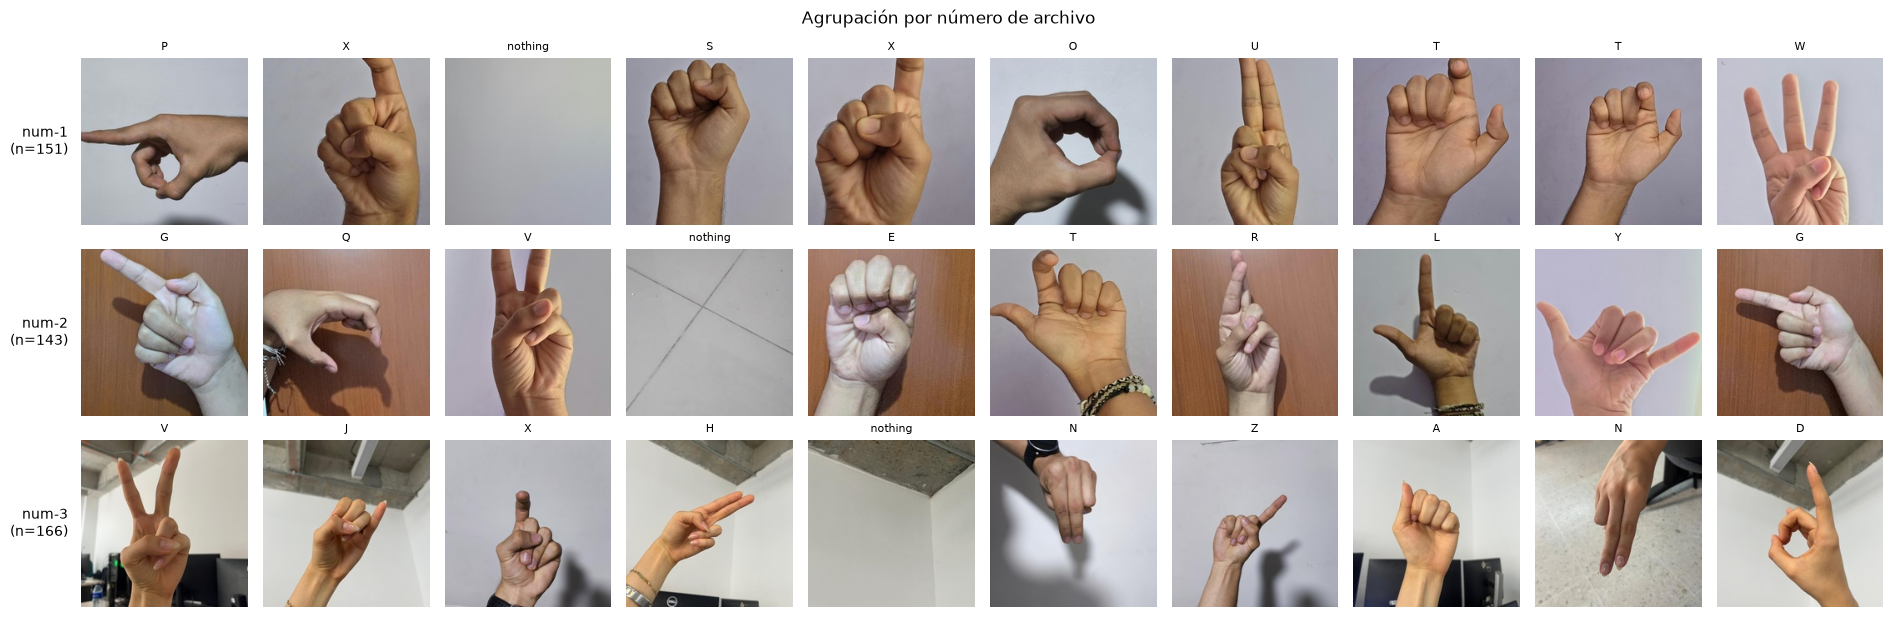

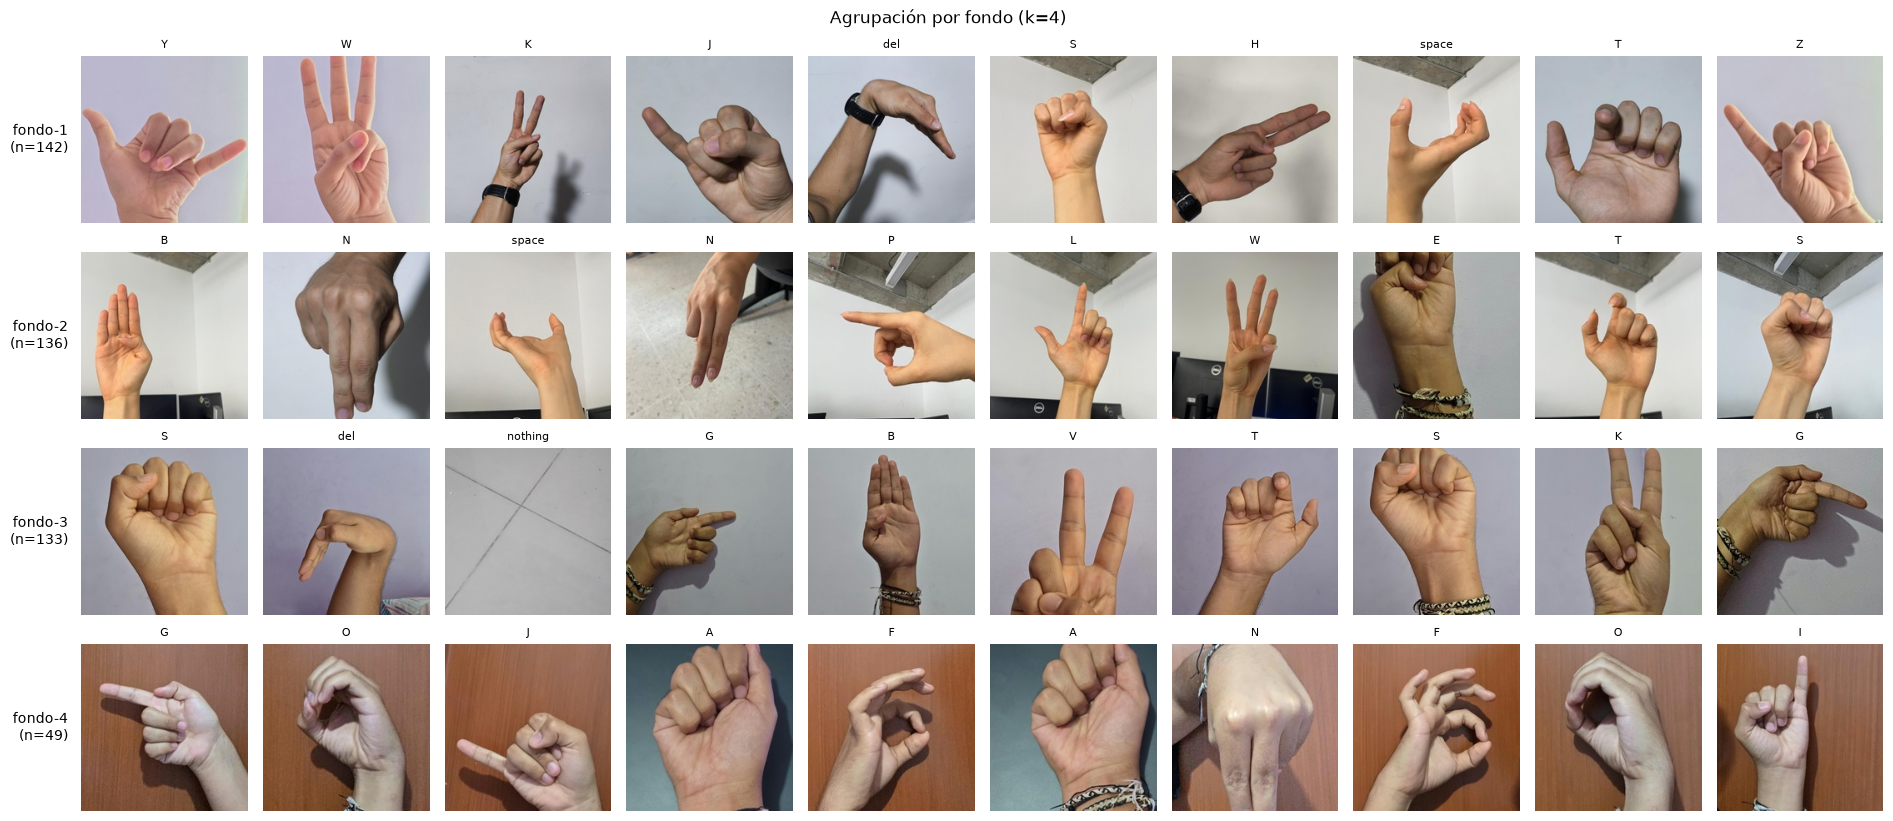

In [3]:
K_FONDO = 4

por_numero = assign_sessions(photos, "numero")
por_fondo = assign_sessions(photos, "fondo", k=K_FONDO)

display(pd.crosstab(por_numero.sesion, por_fondo.sesion))
contact_sheet(por_numero, title="Agrupación por número de archivo")
contact_sheet(por_fondo, title=f"Agrupación por fondo (k={K_FONDO})")

### Elige la agrupación
Mira las hojas de contacto y la tabla cruzada, y decide:
- Si las filas por **número** son coherentes (mismo fondo dentro de cada fila) y coinciden con las de fondo, usa `"numero"`: son pocos grupos y fáciles de explicar.
- Si no, usa `"fondo"` y ajusta `K_FONDO` hasta que cada fila parezca un fondo distinto.

La elección se guarda en `data/sesiones.csv`, que lee el notebook 07.

In [4]:
METODO = "numero"   # "numero" o "fondo"

photos = por_numero if METODO == "fondo" else por_fondo
save_sessions(photos, NORM, SESIONES_CSV)
photos.sesion.value_counts().sort_index().to_frame("fotos").T

sesion,fondo-1,fondo-2,fondo-3,fondo-4
fotos,142,136,133,49


## Paso 3 · Punto de partida: accuracy por sesión
Se cargan los tres modelos y se evalúan con las fotos normalizadas. Además del accuracy se miden:
- **Confianza media en errores:** si es alta, el modelo se equivoca con seguridad.
- **Clase refugio:** la clase que más predice el modelo y qué porcentaje de las predicciones concentra (con 29 clases, un reparto parejo daría ~3,4 %).
- **Accuracy por sesión:** si cambia mucho entre sesiones, el modelo depende del fondo o de la persona.

El accuracy global debe parecerse al del notebook 04 (22,6 %, 52,2 % y 58,0 %); pequeñas diferencias vienen de guardar las fotos como JPEG.

In [5]:
modelos, resultados = {}, {}
for nombre, rd in runs.items():
    size = tuple(load_config(rd / "config.yaml")["data"]["img_size"])
    modelos[nombre] = keras.models.load_model(rd / "final" / "model.keras", compile=False)
    resultados[nombre] = predict_own_photos(modelos[nombre], photos, class_names, size)  # (res, imágenes, probs)

true_ids = resultados["Baseline"][0].true_id.to_numpy()
base = pd.DataFrame({n: imp.own_metrics(r[0]) for n, r in resultados.items()}).T
display(base)

I0000 00:00:1794683466.461358    1369 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:10:00.0, compute capability: 8.9
I0000 00:00:1794683468.475138    1550 cuda_dnn.cc:461] Loaded cuDNN version 92700


,accuracy,confianza media en errores,clase refugio,% predicciones a la refugio,acc fondo-1,acc fondo-2,acc fondo-3,acc fondo-4
Baseline,0.2196,0.838,A,0.17,0.239,0.265,0.18,0.143
MobileNetV2,0.5391,0.795,S,0.107,0.577,0.544,0.586,0.286
EfficientNetB0,0.5804,0.789,S,0.161,0.606,0.588,0.602,0.429


## Paso 4 · Barrido de zoom
Cada foto se acerca o se aleja (factor > 1 acerca, < 1 aleja) y se mide el accuracy a cada escala.

**Cómo leerlo:** si el accuracy **sube** a alguna escala distinta de 1,0, los modelos son sensibles a la escala de la mano y un aumento de datos con más zoom debería ayudar. Si **cae** rápido al alejarse del 1,0 en ambos sentidos, también lo son. Si queda **plano**, la escala no es el problema.

,Baseline,MobileNetV2,EfficientNetB0
zoom,,,
0.60,20.4,39.3,49.8
0.80,24.6,54.8,57.2
1.00,22.0,53.9,58.0
1.25,19.8,50.7,52.8
1.50,16.3,44.1,45.9
2.00,13.3,31.5,35.7


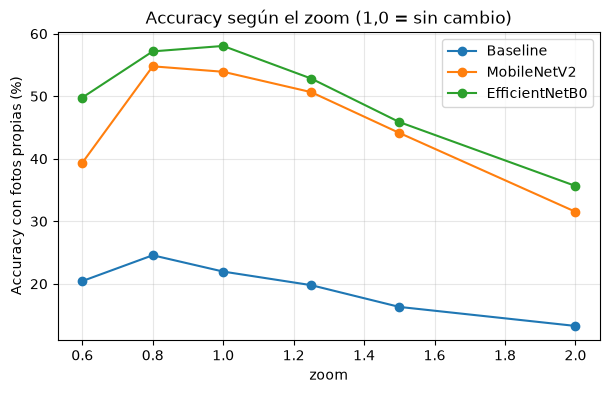

In [6]:
ESCALAS = [0.6, 0.8, 1.0, 1.25, 1.5, 2.0]

probs_escala = {n: imp.predict_scales(modelos[n], resultados[n][1], ESCALAS) for n in modelos}
barrido = pd.DataFrame({n: {s: imp.accuracy(p, true_ids) for s, p in ps.items()} for n, ps in probs_escala.items()})
barrido.index.name = "zoom"
display((barrido * 100).round(1))

ax = (barrido * 100).plot(marker="o", figsize=(7, 4))
ax.set_ylabel("Accuracy con fotos propias (%)")
ax.set_title("Accuracy según el zoom (1,0 = sin cambio)")
ax.grid(alpha=0.3)
plt.show()

## Paso 5 · TTA multiescala
*Test-time augmentation*: en vez de una sola predicción por foto, se promedian las probabilidades a varias escalas. No cuesta entrenar nada. Las escalas del TTA deben estar incluidas en `ESCALAS` del paso anterior; elige las que mejor salieron en el barrido.

In [7]:
ESCALAS_TTA = [0.8, 1.0, 1.25]
assert all(s in ESCALAS for s in ESCALAS_TTA), "ESCALAS_TTA debe estar dentro de ESCALAS"

tta = pd.DataFrame({
    n: {"sin TTA": imp.accuracy(probs_escala[n][1.0], true_ids),
        "con TTA": imp.accuracy(imp.tta_probs(probs_escala[n], ESCALAS_TTA), true_ids)}
    for n in modelos}).T
tta["cambio (puntos)"] = ((tta["con TTA"] - tta["sin TTA"]) * 100).round(1)
display(tta.round(4))

,sin TTA,con TTA,cambio (puntos)
Baseline,0.2196,0.2196,0.0
MobileNetV2,0.5391,0.5391,0.0
EfficientNetB0,0.5804,0.5913,1.1


## Paso 6 · Ensamble
Promediar las probabilidades de varios modelos. Funciona cuando se equivocan en fotos distintas. Se prueba con y sin TTA. El Baseline suele empeorar el ensamble por ser mucho más débil: por eso se comparan los dos combos.

In [8]:
def acc_ens(miembros, usar_tta):
    if usar_tta:
        p = np.mean([imp.tta_probs(probs_escala[m], ESCALAS_TTA) for m in miembros], axis=0)
    else:
        p = np.mean([probs_escala[m][1.0] for m in miembros], axis=0)
    return imp.accuracy(p, true_ids)

combos = {"MobileNetV2 + EfficientNetB0": ["MobileNetV2", "EfficientNetB0"], "Los tres": list(modelos)}
ensamble = pd.DataFrame({n: {"sin TTA": acc_ens(m, False), "con TTA": acc_ens(m, True)} for n, m in combos.items()}).T

resumen = pd.concat([tta[["sin TTA", "con TTA"]].rename(index=lambda n: f"{n} (solo)"), ensamble])
display((resumen * 100).round(1))

,sin TTA,con TTA
Baseline (solo),22.0,22.0
MobileNetV2 (solo),53.9,53.9
EfficientNetB0 (solo),58.0,59.1
MobileNetV2 + EfficientNetB0,60.0,61.1
Los tres,58.9,60.2


## Paso 7 · Grad-CAM: ¿dónde mira el modelo?
Mapa de calor de la zona que más apoya la clase predicha (rojo = más influencia). Se muestran errores y aciertos del modelo elegido.

**Cómo leerlo:**
- Si en los **errores** el calor cae sobre el **fondo** (paredes, monitores, el borde de la imagen), el modelo se apoya en el entorno y no en la mano: refuerza la necesidad de variar fondos al entrenar.
- Si cae sobre la **mano** pero se equivoca, la confusión es de forma (por ejemplo, puños cerrados parecidos).
- Compara con los **aciertos**: si ahí el calor sí está en la mano, la diferencia es informativa.

Los mapas son de baja resolución (la última capa de la red es de pocos píxeles), así que indican la zona general, no el detalle.

EfficientNetB0: errores (193 en total)


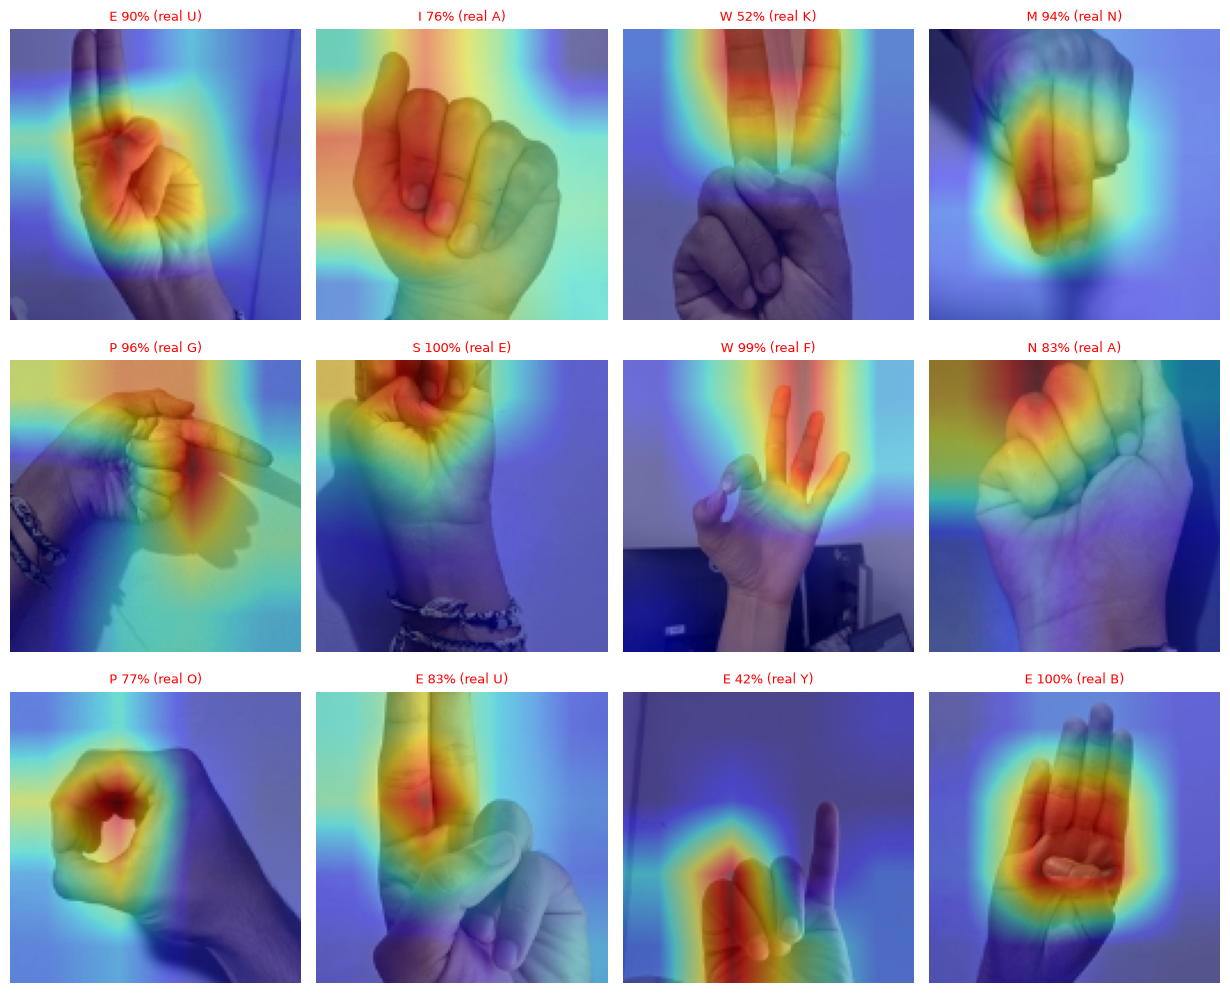

EfficientNetB0: aciertos (267 en total)


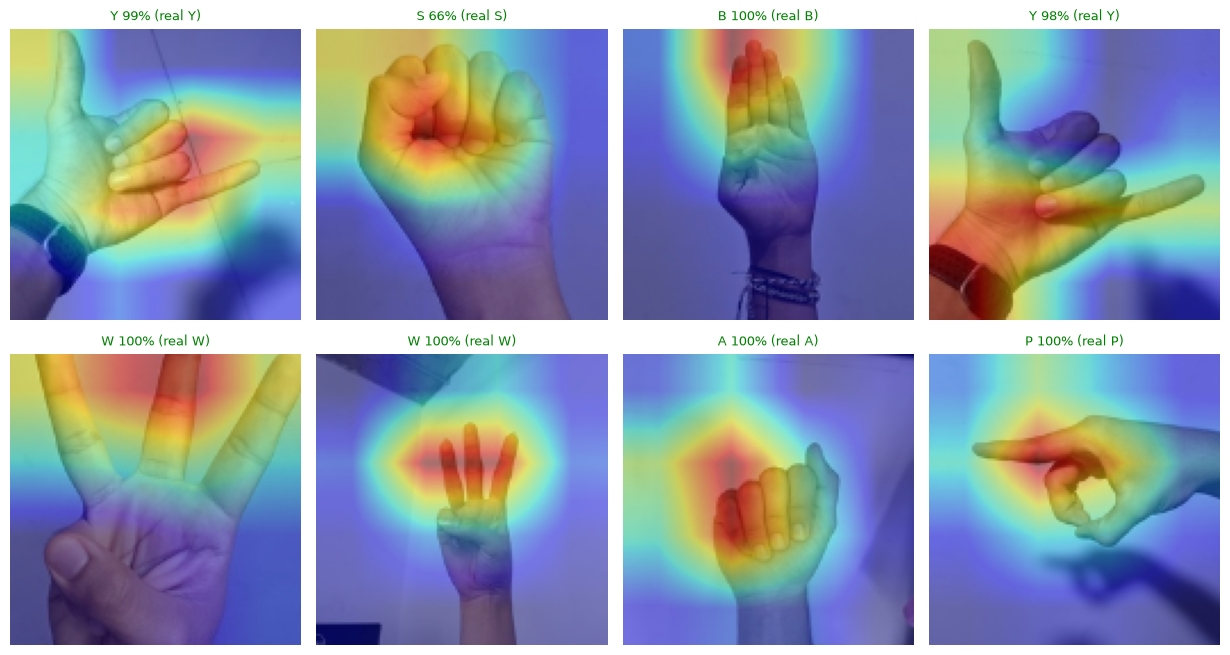

In [9]:
modelo = "EfficientNetB0"   # "Baseline" / "MobileNetV2" / "EfficientNetB0"
res, images, _ = resultados[modelo]
rng = np.random.default_rng(0)

errores = res.index[~res.correct].to_numpy()
aciertos = res.index[res.correct].to_numpy()

for titulo, ids, n in (("errores", errores, 12), ("aciertos", aciertos, 8)):
    print(f"{modelo}: {titulo} ({len(ids)} en total)")
    if len(ids):
        imp.plot_gradcam(modelos[modelo], images, true_ids, class_names, rng.choice(ids, min(n, len(ids)), replace=False))

## Resumen *(completar)*
- **Accuracy por sesión:** ¿varía mucho entre sesiones? …
- **Zoom:** ¿hay una escala mejor que 1,0? …
- **TTA:** ¿mejora, y cuánto? …
- **Ensamble:** ¿mejora frente al mejor modelo individual? …
- **Grad-CAM:** ¿mira la mano o el fondo? …
- **Conclusión y siguiente paso:** … (continúa en el notebook 07)

> Recuerda que con ~460 fotos y un accuracy cercano al 50 %, diferencias de 2-3 puntos pueden ser ruido.